# Diagnóstico no conjunto de validação (Etapa 7)

Lê `execucoes/*_j120_c128_s?` (as 30 execuções do estudo + o que houver) e mostra, **só na validação**:

1. tabela de métricas × ingênuo; 2. curvas de perda; 3. previsto × real; 4. retorno previsto × real
   (o modelo prevê algo ou copia o dia anterior?); 5. probabilidades do FinGAT; 6. direção × base.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path("execucoes")
assert BASE.is_dir(), "rode o notebook a partir de projeto/"
pastas = sorted(
    p for p in BASE.glob("*_j120_c128_s?") if (p / "metricas.json").exists()
)


def cfg(p: Path) -> str:
    return p.name.rsplit("_s", 1)[0]


m = {p.name: json.load(open(p / "metricas.json")) for p in pastas}
logs = {p.name: pd.read_csv(p / "log.csv") for p in pastas}
val = {
    p.name: pd.read_csv(p / "previsoes_validacao.csv", parse_dates=["data"])
    for p in pastas
}
configs = sorted({cfg(p) for p in pastas})
regressao = [c for c in configs if not c.startswith("fingat")]
fingat = [c for c in configs if c.startswith("fingat")]
print(len(pastas), "execuções:", {c: sum(cfg(p) == c for p in pastas) for c in configs})

30 execuções: {'fingat_artigo_j120_c128': 5, 'fingat_repo_j120_c128': 5, 'gru_ohlcv_j120_c128': 5, 'hdfm_diferenca_causal_j120_c128': 5, 'hdfm_diferenca_inteira_j120_c128': 5, 'hdfm_minmax_causal_j120_c128': 5}


In [2]:
# 1. métricas de validação por configuração (média ± dp entre sementes) e o ingênuo
linhas = []
for nome, d in m.items():
    linhas.append(
        {
            "config": cfg(BASE / nome),
            "semente": d["semente"],
            "melhor_epoca": d["melhor_epoca"],
            **d["validacao"],
        }
    )
tab = pd.DataFrame(linhas)
ing = next(
    d["validacao_ingenuo"] for d in m.values() if "rmse" in d["validacao_ingenuo"]
)  # o do FinGAT só tem direção
print(
    "ingênuo (amanhã = hoje; direção = sempre alta):",
    {k: round(v, 4) for k, v in ing.items()},
)
tab.drop(columns="semente").groupby("config").agg(["mean", "std"]).round(4)

ingênuo (amanhã = hoje; direção = sempre alta): {'rmse': 0.7118, 'mae': 0.5367, 'mape': 1.401, 'r2': 0.9891, 'acuracia_direcao': 0.664, 'acmape': 0.686}


melhor_epoca          acuracia_direcao  \
                                         mean      std             mean   
config                                                                    
fingat_artigo_j120_c128                  80.2  21.6495           0.6640   
fingat_repo_j120_c128                    77.4  17.4011           0.6640   
gru_ohlcv_j120_c128                      48.2  32.0422           0.6560   
hdfm_diferenca_causal_j120_c128          41.4   3.9115           0.5520   
hdfm_diferenca_inteira_j120_c128         45.8  11.2116           0.9040   
hdfm_minmax_causal_j120_c128             93.8   7.4967           0.4976   

                                         acuracia_direcao_todas       \
                                     std                   mean  std   
config                                                                 
fingat_artigo_j120_c128           0.0000                 0.5173  0.0   
fingat_repo_j120_c128             0.0000                 0.5173  0.0   
gru_ohlcv_j120_c128               0.0420                    NaN  NaN   
hdfm_diferenca_causal_j120_c128   0.0126                    NaN  NaN   
hdfm_diferenca_inteira_j120_c128  0.0080                    NaN  NaN   
hdfm_minmax_causal_j120_c128      0.0191                    NaN  NaN   

                                 acuracia_direcao_todas_sinal_retorno         \
                                                                 mean    std   
config                                                                         
fingat_artigo_j120_c128                                        0.5035  0.019   
fingat_repo_j120_c128                                          0.5035  0.019   
gru_ohlcv_j120_c128                                               NaN    NaN   
hdfm_diferenca_causal_j120_c128                                   NaN    NaN   
hdfm_diferenca_inteira_j120_c128                                  NaN    NaN   
hdfm_minmax_causal_j120_c128                                      NaN    NaN   

                                    rmse             mae            mape  \
                                    mean     std    mean     std    mean   
config                                                                     
fingat_artigo_j120_c128              NaN     NaN     NaN     NaN     NaN   
fingat_repo_j120_c128                NaN     NaN     NaN     NaN     NaN   
gru_ohlcv_j120_c128               0.6860  0.0039  0.4992  0.0052  1.3021   
hdfm_diferenca_causal_j120_c128   1.0231  0.0322  0.7702  0.0242  2.0301   
hdfm_diferenca_inteira_j120_c128  0.1910  0.0052  0.1433  0.0040  0.3654   
hdfm_minmax_causal_j120_c128      1.6065  0.1151  1.2292  0.0985  3.0909   

                                              r2          acmape          
                                     std    mean     std    mean     std  
config                                                                    
fingat_artigo_j120_c128              NaN     NaN     NaN     NaN     NaN  
fingat_repo_j120_c128                NaN     NaN     NaN     NaN     NaN  
gru_ohlcv_j120_c128               0.0173  0.9899  0.0001  0.7010  0.0841  
hdfm_diferenca_causal_j120_c128   0.0633  0.9775  0.0014  0.9163  0.0256  
hdfm_diferenca_inteira_j120_c128  0.0100  0.9992  0.0000  0.1957  0.0161  
hdfm_minmax_causal_j120_c128      0.2203  0.9442  0.0080  1.0357  0.0402

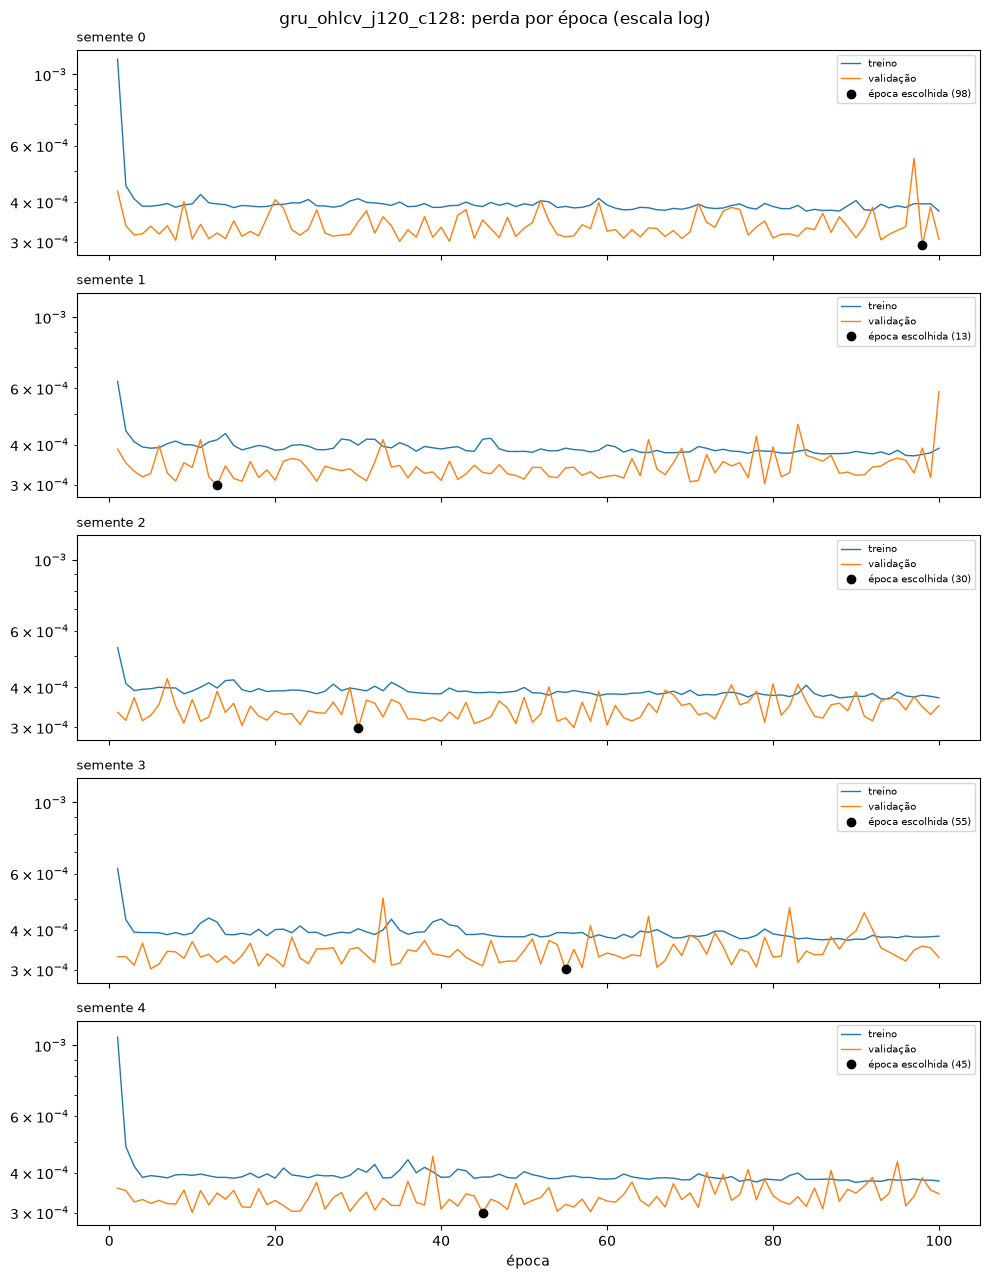

In [3]:
# 2. curvas de perda, um gráfico por semente: treino × validação.
# Ponto = época escolhida (a é a de menor perda de validação)
MODELO = "gru_ohlcv_j120_c128"  # um dos valores de tab["config"]

opcoes = sorted(set(tab["config"]))
assert MODELO in opcoes, f"MODELO deve ser um de {opcoes}"
nomes = sorted(n for n in logs if cfg(BASE / n) == MODELO)
fig, eixos = plt.subplots(
    len(nomes),
    1,
    figsize=(10, 2.6 * len(nomes)),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for ax, nome in zip(eixos[:, 0], nomes, strict=True):
    lg = logs[nome]
    ax.plot(lg["epoca"], lg["perda_treino"], color="C0", lw=1, label="treino")
    ax.plot(lg["epoca"], lg["perda_validacao"], color="C1", lw=1, label="validação")
    e = m[nome]["melhor_epoca"]
    ax.plot(
        e,
        lg.loc[lg["epoca"] == e, "perda_validacao"],
        "o",
        color="k",
        label=f"época escolhida ({e})",
    )
    ax.set_yscale("log")
    ax.set_title(f"semente {m[nome]['semente']}", fontsize=9, loc="left")
    ax.legend(fontsize=7, loc="upper right")
eixos[-1, 0].set_xlabel("época")
fig.suptitle(f"{MODELO}: perda por época (escala log)")
fig.tight_layout()

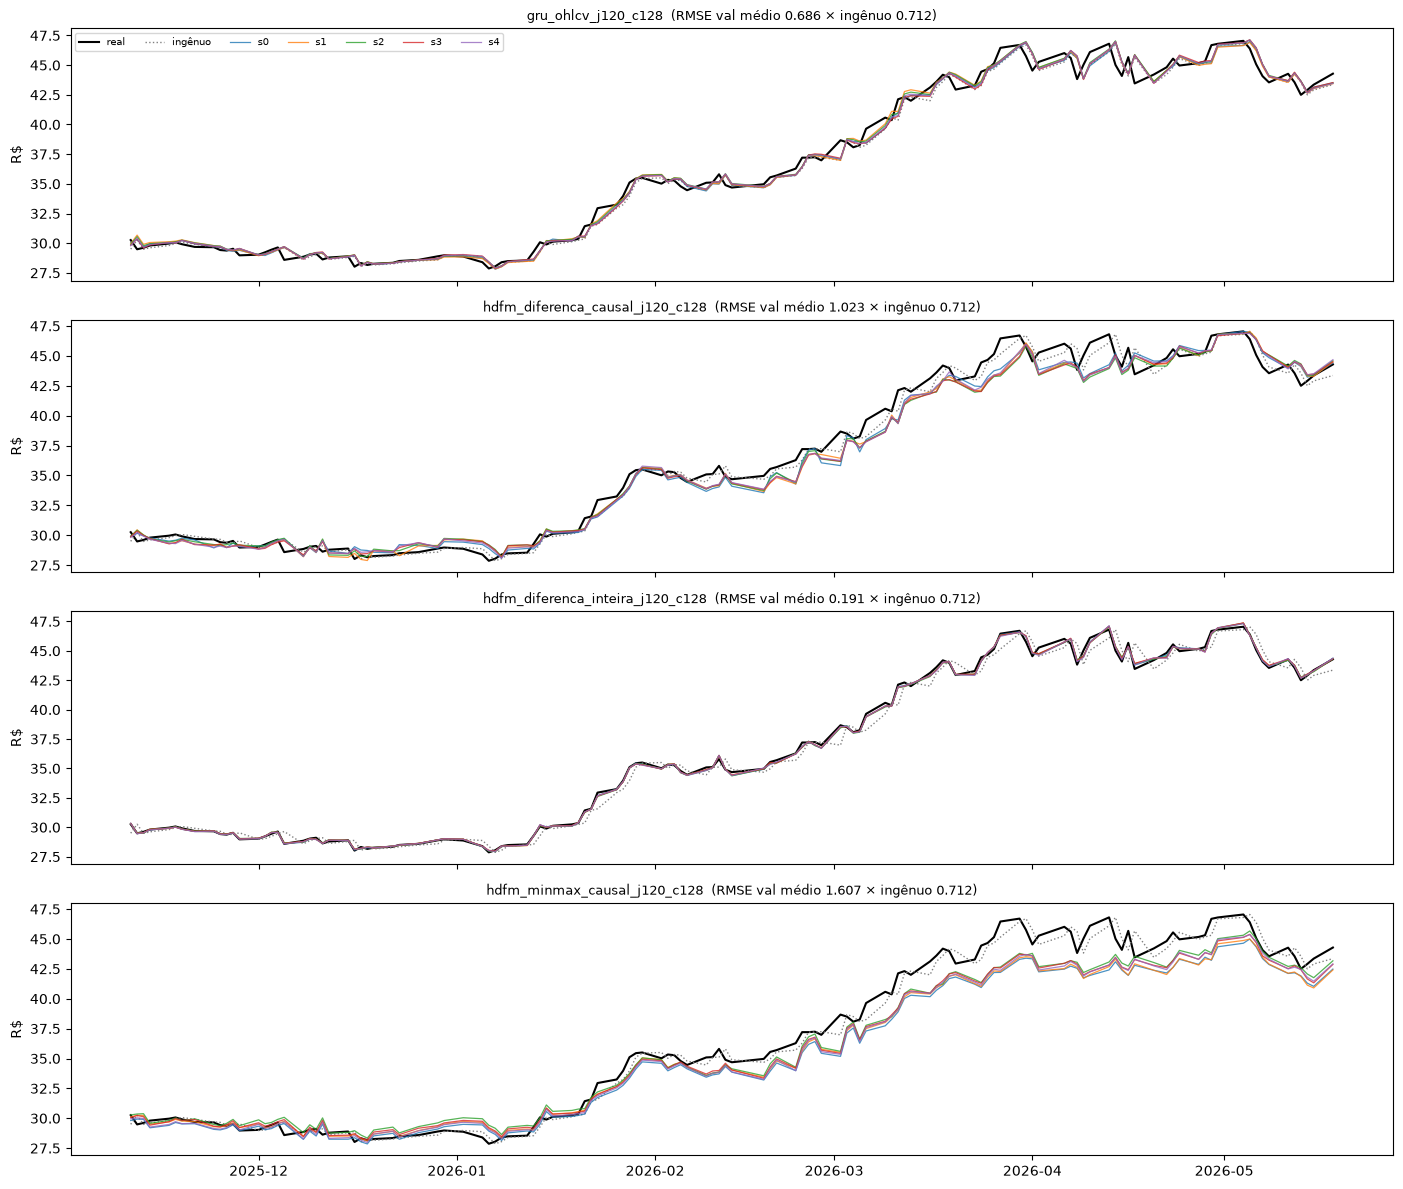

In [4]:
# 3. previsto × real na validação (todas as sementes),
# com o ingênuo (= real deslocado 1 dia)
fig, eixos = plt.subplots(
    len(regressao), 1, figsize=(14, 3 * len(regressao)), sharex=True, squeeze=False
)
for ax, c in zip(eixos[:, 0], regressao, strict=False):
    nomes = [n for n in val if cfg(BASE / n) == c]
    v0 = val[nomes[0]]
    ax.plot(v0["data"], v0["real"], color="k", lw=1.5, label="real")
    ax.plot(v0["data"], v0["anterior"], color="gray", lw=1, ls=":", label="ingênuo")
    for i, n in enumerate(nomes):
        ax.plot(
            val[n]["data"],
            val[n]["previsto"],
            lw=0.9,
            color=f"C{i}",
            alpha=0.8,
            label=f"s{m[n]['semente']}",
        )
    ax.set_title(
        f"{c}  (RMSE val médio {tab.loc[tab.config == c, 'rmse'].mean():.3f}"
        f" × ingênuo {ing['rmse']:.3f})",
        fontsize=9,
    )
    ax.set_ylabel("R$")
eixos[0, 0].legend(ncol=8, fontsize=7)
fig.tight_layout()

,corr_retornos,dp_ret_previsto,dp_ret_real,media_ret_previsto,media_ret_real,frac_prev_alta,frac_real_alta
config,,,,,,,
gru_ohlcv_j120_c128,0.2220,0.1308,0.7047,0.1370,0.1183,0.8864,0.664
hdfm_diferenca_causal_j120_c128,0.0225,0.6715,0.7047,-0.2383,0.1183,0.4272,0.664
hdfm_diferenca_inteira_j120_c128,0.9687,0.6095,0.7047,0.0917,0.1183,0.6192,0.664
hdfm_minmax_causal_j120_c128,0.0768,1.1096,0.7047,-0.8665,0.1183,0.2736,0.664


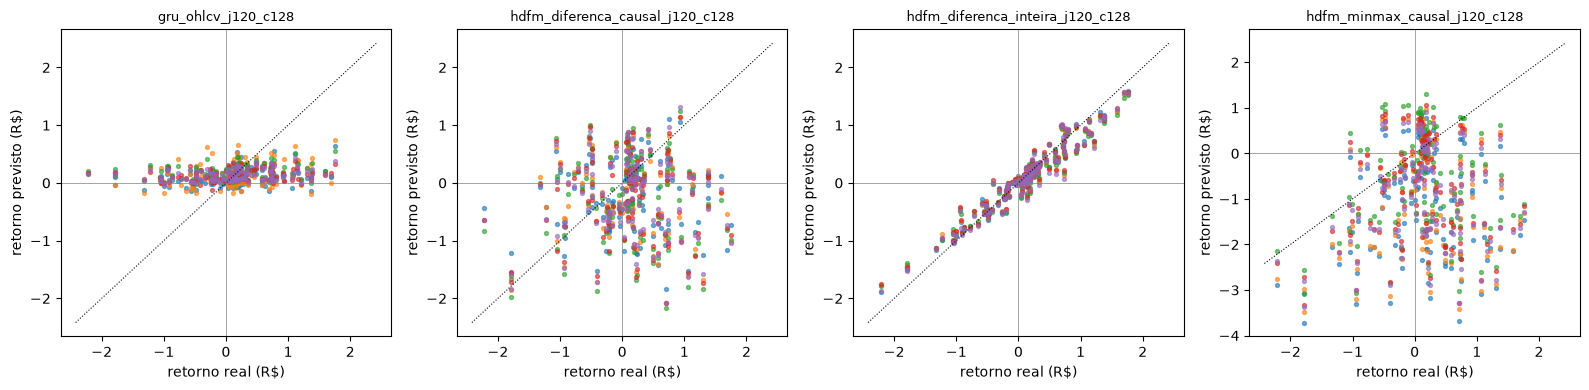

In [5]:
# 4. retorno previsto (previsto − anterior) × retorno real (real − anterior).
# Se a nuvem é uma linha horizontal perto de 0, o modelo só copia o dia anterior.
# corr ≈ 0 → nenhum sinal; inclinação ≠ 1 é normal, mas o sinal da correlação importa.
fig, eixos = plt.subplots(
    1, len(regressao), figsize=(4 * len(regressao), 4), squeeze=False
)
diag = []
for ax, c in zip(eixos[0], regressao, strict=False):
    for i, n in enumerate(n for n in val if cfg(BASE / n) == c):
        v = val[n]
        rp, rr = v["previsto"] - v["anterior"], v["real"] - v["anterior"]
        ax.scatter(rr, rp, s=8, alpha=0.6, color=f"C{i}")
        diag.append(
            {
                "config": c,
                "semente": m[n]["semente"],
                "corr_retornos": np.corrcoef(rp, rr)[0, 1],
                "dp_ret_previsto": rp.std(),
                "dp_ret_real": rr.std(),
                "media_ret_previsto": rp.mean(),
                "media_ret_real": rr.mean(),
                "frac_prev_alta": (rp >= 0).mean(),
                "frac_real_alta": (rr >= 0).mean(),
            }
        )
    lim = np.abs(ax.get_xlim()).max()
    ax.plot([-lim, lim], [-lim, lim], "k:", lw=0.8)
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("retorno real (R$)")
    ax.set_ylabel("retorno previsto (R$)")
fig.tight_layout()
pd.DataFrame(diag).drop(columns="semente").groupby("config").mean().round(4)

fingat_artigo_j120_c128_s0: prob min 0.5074 max 0.5074 dp 0.00001 | frac ≥0,5: 1.000
fingat_artigo_j120_c128_s1: prob min 0.5064 max 0.5065 dp 0.00003 | frac ≥0,5: 1.000
fingat_artigo_j120_c128_s2: prob min 0.5070 max 0.5071 dp 0.00001 | frac ≥0,5: 1.000
fingat_artigo_j120_c128_s3: prob min 0.5068 max 0.5068 dp 0.00001 | frac ≥0,5: 1.000
fingat_artigo_j120_c128_s4: prob min 0.5074 max 0.5074 dp 0.00001 | frac ≥0,5: 1.000
fingat_repo_j120_c128_s0: prob min 0.5155 max 0.5155 dp 0.00000 | frac ≥0,5: 1.000
fingat_repo_j120_c128_s1: prob min 0.5133 max 0.5133 dp 0.00000 | frac ≥0,5: 1.000
fingat_repo_j120_c128_s2: prob min 0.5216 max 0.5216 dp 0.00000 | frac ≥0,5: 1.000
fingat_repo_j120_c128_s3: prob min 0.5232 max 0.5232 dp 0.00000 | frac ≥0,5: 1.000
fingat_repo_j120_c128_s4: prob min 0.5124 max 0.5124 dp 0.00000 | frac ≥0,5: 1.000


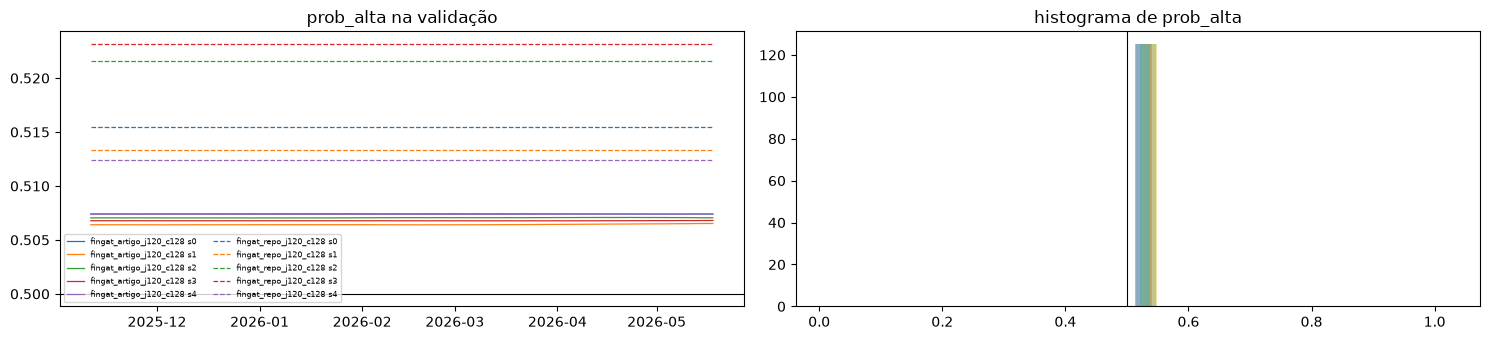

In [6]:
# 5. FinGAT: probabilidade de alta da PETR4 por dia.
# Constante ≥ 0,5 = colapsou em "sempre alta"
# (a acurácia então é exatamente a fração de dias de alta, igual ao ingênuo).
if fingat:
    fig, eixos = plt.subplots(1, 2, figsize=(15, 3.5))
    for j, c in enumerate(fingat):
        for i, n in enumerate(n for n in val if cfg(BASE / n) == c):
            p = val[n]["prob_alta"]
            eixos[0].plot(
                val[n]["data"],
                p,
                lw=0.9,
                ls="-" if j == 0 else "--",
                color=f"C{i}",
                label=f"{c} s{m[n]['semente']}",
            )
            eixos[1].hist(p, bins=40, alpha=0.4, label=f"{c} s{m[n]['semente']}")
            print(
                f"{n}: prob min {p.min():.4f} max {p.max():.4f} dp {p.std():.5f}"
                f" | frac ≥0,5: {(p >= 0.5).mean():.3f}"
            )
    eixos[0].axhline(0.5, color="k", lw=0.8)
    eixos[0].set_title("prob_alta na validação")
    eixos[0].legend(fontsize=6, ncol=2)
    eixos[1].axvline(0.5, color="k", lw=0.8)
    eixos[1].set_title("histograma de prob_alta")
    fig.tight_layout()

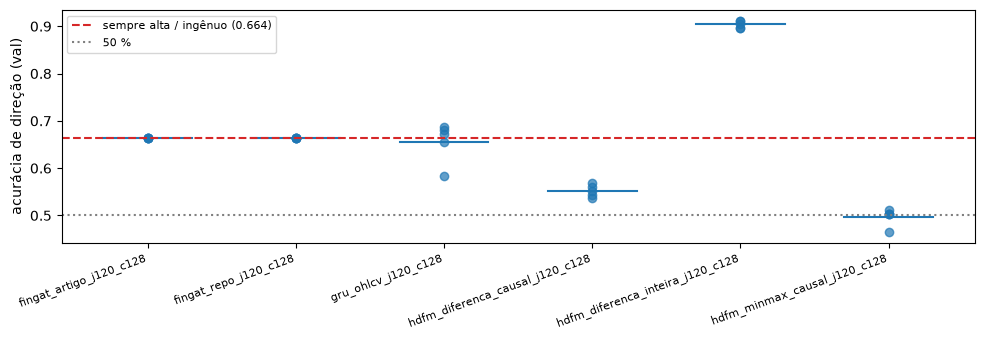

In [7]:
# 6. acurácia de direção na validação por execução,
# contra "sempre alta" (= ingênuo) e 50 %
fig, ax = plt.subplots(figsize=(10, 3.5))
for i, c in enumerate(configs):
    y = tab.loc[tab.config == c, "acuracia_direcao"]
    ax.scatter([i] * len(y), y, color="C0", alpha=0.7)
    ax.plot([i - 0.3, i + 0.3], [y.mean()] * 2, color="C0")
ax.axhline(
    ing["acuracia_direcao"],
    color="C3",
    ls="--",
    label=f"sempre alta / ingênuo ({ing['acuracia_direcao']:.3f})",
)
ax.axhline(0.5, color="gray", ls=":", label="50 %")
ax.set_xticks(range(len(configs)), configs, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("acurácia de direção (val)")
ax.legend(fontsize=8)
fig.tight_layout()

In [8]:
# 7. época escolhida por execução: perto de 100 = ainda melhorando (treino curto?);
# perto de 1 = nunca aprendeu
tab.pivot_table(index="config", columns="semente", values="melhor_epoca")

semente,0,1,2,3,4
config,,,,,
fingat_artigo_j120_c128,95.0,51.0,63.0,98.0,94.0
fingat_repo_j120_c128,100.0,58.0,62.0,81.0,86.0
gru_ohlcv_j120_c128,98.0,13.0,30.0,55.0,45.0
hdfm_diferenca_causal_j120_c128,42.0,44.0,35.0,45.0,41.0
hdfm_diferenca_inteira_j120_c128,57.0,41.0,30.0,45.0,56.0
hdfm_minmax_causal_j120_c128,94.0,96.0,81.0,100.0,98.0
